# Supplementary: application fluxes and available cropland 

The GCAM central 1.5C schedule (`exe_central1p5`) peaks at 4.6 Gt CO2/yr of gross CDR, but doesn't offer underlying application fluxes (i.e., dosing per hectare). We do the converstion by just dividing by the available cropland area.

1. Cropland required by each GCAM region at three fixed application fluxes
2. Application fluxes picked by the best (no land limit) and best (land limit) optima
3. CDF of the cropland under ERW against application flux, best (land limit)
4. Map of peak application flux by region

In [4]:
import os
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

EXP_SET, DEG_RES = "exe_central1p5", 1
S3_GCAM = ("s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/"
           f"one-cell-per-region/{EXP_SET}")
S3_RUN  = ("s3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/gcam/"
           f"gcam_opr_full2_cec1/{EXP_SET}_001_multiSchedule/{EXP_SET}")
ROCK_FN = f"annual_rockflx_densest-ag-region_{DEG_RES}deg.pkl"

FIXED_RATES  = [5.0, 15.0, 30.0]   # t/ha/yr; each needs a <rate>-tHaYr-appRate-FIXED dir on S3
CDF_YEARS    = [2025, 2035, 2045, 2099]   # the SCEPTER runs are 80 yr: 2020-2099
CROPFRAC_MAX = 1.0                 # land limit: max fraction of regional cropland under ERW
CEC_FACTOR   = 1.0                 # the cec_factor slice plotted in fx-bestCdrCurves
START_YEAR   = 2020

SAVE_ON  = True
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
savehere = REPO / "figures/supp/panels"
savehere.mkdir(parents=True, exist_ok=True)

FS_LAB, FS_TICK, FS_TITLE, FS_LEG = 13, 11, 13, 10

## 1. Cropland required at a fixed application flux

In [5]:
dfs = {r: pd.read_pickle(os.path.join(S3_GCAM, f"{r}-tHaYr-appRate-FIXED", ROCK_FN))
       for r in FIXED_RATES}
regions = np.sort(dfs[FIXED_RATES[0]]["region_nospaces"].unique())
print(f"{len(regions)} regions, {dfs[FIXED_RATES[0]]['time'].min()}-{dfs[FIXED_RATES[0]]['time'].max()}")

32 regions, 2020-2100


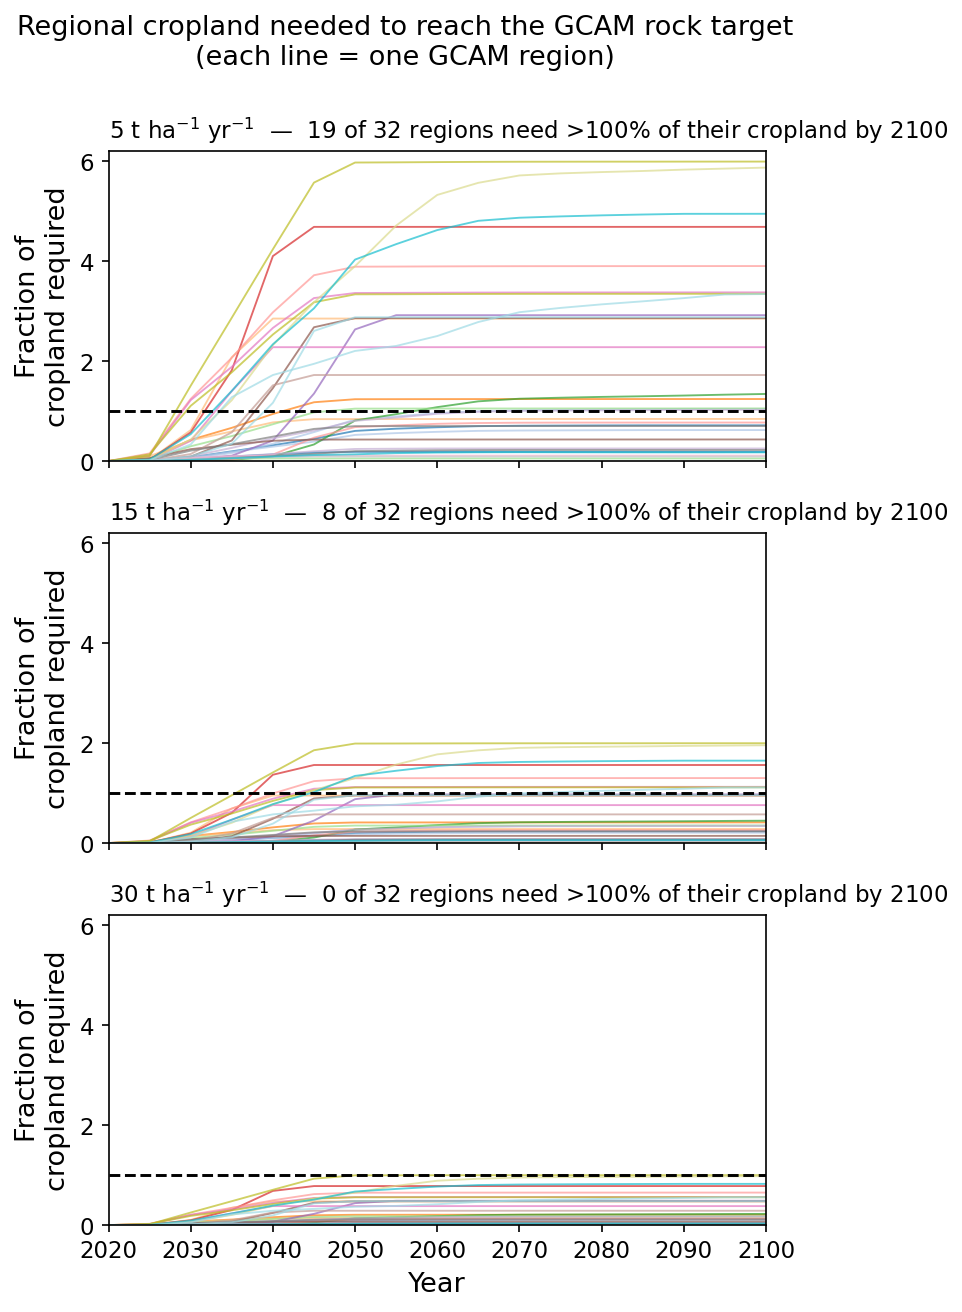

In [6]:
YLIM = (0, 6.2)
reg_colors = plt.get_cmap("tab20", len(regions))

fig, axes = plt.subplots(len(FIXED_RATES), 1, figsize=(5.5, 2.9 * len(FIXED_RATES)),
                         dpi=150, sharex=True, sharey=True, squeeze=False)
axes = axes.ravel()

for ax, rate in zip(axes, FIXED_RATES):
    piv = dfs[rate].pivot_table(index="time", columns="region_nospaces",
                                values="cropland_fraction_required")
    for i, reg in enumerate(regions):
        ax.plot(piv.index, piv[reg], color=reg_colors(i), lw=0.9, alpha=0.7)
    ax.axhline(1.0, color="black", lw=1.4, ls="--", zorder=5)

    n_over = int((piv.loc[piv.index.max()] > 1).sum())
    ax.set_title(f"{rate:g} t ha$^{{-1}}$ yr$^{{-1}}$  —  {n_over} of {len(regions)} regions "
                 "need >100% of their cropland by 2100", fontsize=FS_TITLE - 2, loc="left")
    ax.set_ylabel("Fraction of\ncropland required", fontsize=FS_LAB)
    ax.set_ylim(YLIM)
    ax.tick_params(labelsize=FS_TICK)

axes[-1].set_xlabel("Year", fontsize=FS_LAB)
axes[-1].set_xlim(piv.index.min(), piv.index.max())
fig.suptitle("Regional cropland needed to reach the GCAM rock target\n(each line = one GCAM region)",
             fontsize=FS_TITLE, y=1.0)
plt.tight_layout()
plt.show()

if SAVE_ON:
    fig.savefig(os.path.join(savehere, "appflux-cropland-required.png"),
                dpi=300, bbox_inches="tight")

## 2. Application fluxes chosen with and without the land limit

In [8]:
LOAD_VARS = ["cdr_adv_region", "cropfrac_ERW", "cropland_ha_total"]
OPT_DIMS  = ("apprate_base", "dustrad")

dssum = (xr.open_zarr(os.path.join(S3_RUN, "ds_cdr_globalScaling_constApp_SUM.zarr"))[LOAD_VARS]
         .sel(cec_factor=CEC_FACTOR, drop=True).load())


def _pick(ds, metric):
    """Vectorized joint argmax over OPT_DIMS, returning the winning slice for every region."""
    stacked = metric.stack(combo=OPT_DIMS)
    pos = stacked.fillna(-np.inf).argmax("combo")
    return ds.sel({d: stacked[d].isel(combo=pos).reset_coords(drop=True) for d in OPT_DIMS})


def optimize(ds, land_limit):
    cdr = ds["cdr_adv_region"].sum("time")
    if not land_limit:
        return _pick(ds, cdr)
    max_cropfrac = ds["cropfrac_ERW"].max("time")
    feasible = max_cropfrac <= CROPFRAC_MAX
    # where nothing fits the land limit, fall back to the least-exceeding combo
    return _pick(ds, xr.where(~feasible.any(dim=OPT_DIMS), -max_cropfrac, cdr.where(feasible)))


best = {"best_nolim": optimize(dssum, False), "best_lim": optimize(dssum, True)}

summary = pd.DataFrame({
    "nolim_flux":     best["best_nolim"].apprate_base.values,
    "lim_flux":       best["best_lim"].apprate_base.values,
    "nolim_cropfrac": best["best_nolim"]["cropfrac_ERW"].max("time").values,
    "lim_cropfrac":   best["best_lim"]["cropfrac_ERW"].max("time").values,
}, index=dssum.site.values).round(2)

print(f"median flux  no land limit {np.median(summary.nolim_flux):g}  ->  "
      f"land limit {np.median(summary.lim_flux):g} t/ha/yr")
print(f"land-infeasible regions: {int((summary.lim_cropfrac > CROPFRAC_MAX).sum())}")
# summary

median flux  no land limit 2.5  ->  land limit 15 t/ha/yr
land-infeasible regions: 0


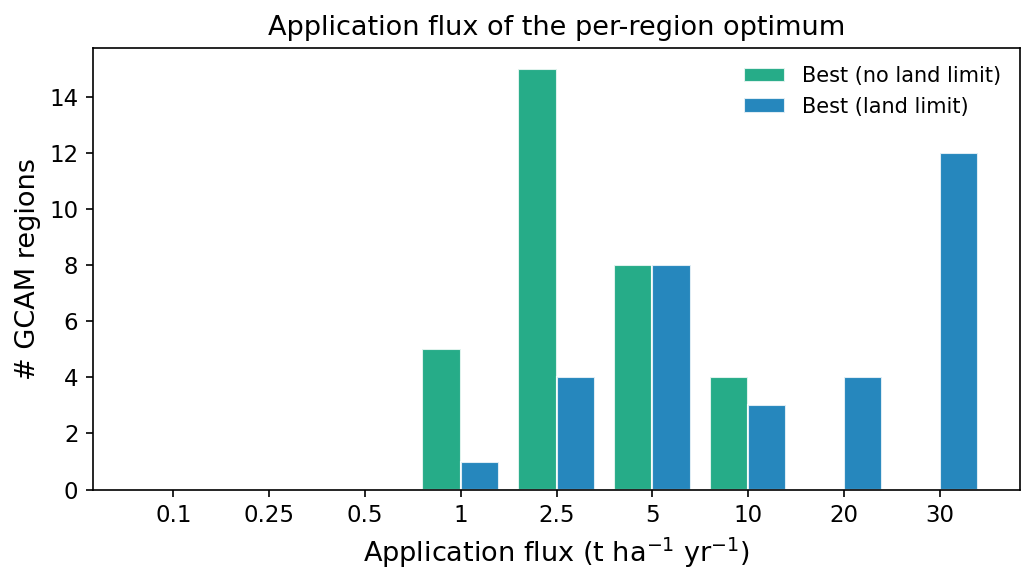

In [9]:
SAVE_ON = False
CASE_LABEL = {"best_nolim": "Best (no land limit)", "best_lim": "Best (land limit)"}
CASE_COLOR = {"best_nolim": "#009E73", "best_lim": "#0072B2"}

rate_levels = dssum.apprate_base.values
pos, width = np.arange(len(rate_levels)), 0.4

fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
for case, offset in zip(CASE_LABEL, [-width / 2, width / 2]):
    counts = [int((best[case].apprate_base.values == r).sum()) for r in rate_levels]
    ax.bar(pos + offset, counts, width, color=CASE_COLOR[case], alpha=0.85,
           edgecolor="white", label=CASE_LABEL[case])

ax.set_xticks(pos)
ax.set_xticklabels([f"{r:g}" for r in rate_levels], fontsize=FS_TICK)
ax.set_xlabel(r"Application flux (t ha$^{-1}$ yr$^{-1}$)", fontsize=FS_LAB)
ax.set_ylabel("# GCAM regions", fontsize=FS_LAB)
ax.tick_params(labelsize=FS_TICK)
ax.legend(fontsize=FS_LEG, frameon=False)
ax.set_title("Application flux of the per-region optimum", fontsize=FS_TITLE)
plt.tight_layout()
plt.show()

if SAVE_ON:
    fig.savefig(os.path.join(savehere, "appflux-hist-landlimit.png"), dpi=300, bbox_inches="tight")

## 3. Cumulative ERW cropland vs application flux

Regions sorted by their application flux; y-axis is the cumulative cropland fraction under ERW at each application rate, scaled to the total cropland under ERW for that year (i.e., for all the cropland receiving rock, how much receives each application rate).

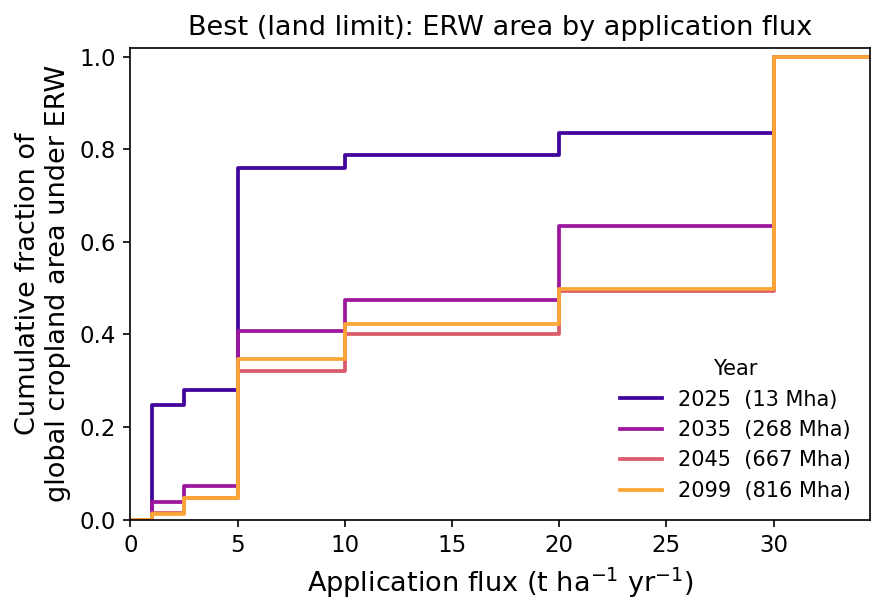

In [10]:
SAVE_ON = True
CDF_CASE = "best_lim"

sel = best[CDF_CASE]
flux = sel.apprate_base.values
order = np.argsort(flux)
year_colors = plt.cm.plasma(np.linspace(0.1, 0.8, len(CDF_YEARS)))

x = np.concatenate([[0], flux[order], [flux.max() * 1.15]])

fig, ax = plt.subplots(figsize=(6, 4.2), dpi=150)
for yr, color in zip(CDF_YEARS, year_colors):
    area = (sel["cropfrac_ERW"].sel(time=yr - START_YEAR) * sel["cropland_ha_total"]).values
    cum = np.cumsum(area[order]) / area.sum()
    ax.plot(x, np.concatenate([[0], cum, [cum[-1]]]), drawstyle="steps-post",
            color=color, lw=1.8, label=f"{yr}  ({area.sum() / 1e6:.0f} Mha)")

ax.set_xlabel(r"Application flux (t ha$^{-1}$ yr$^{-1}$)", fontsize=FS_LAB)
ax.set_ylabel("Cumulative fraction of\nglobal cropland area under ERW", fontsize=FS_LAB)
ax.set_xlim(0, x[-1])
ax.set_ylim(0, 1.02)
ax.tick_params(labelsize=FS_TICK)
ax.legend(title="Year", fontsize=FS_LEG, title_fontsize=FS_LEG, frameon=False)
ax.set_title(f"{CASE_LABEL[CDF_CASE]}: ERW area by application flux", fontsize=FS_TITLE)
plt.tight_layout()
plt.show()

if SAVE_ON:
    fig.savefig(os.path.join(savehere, "appflux-cdf-cropland.png"), dpi=300, bbox_inches="tight")

## 4. Peak application flux by region

`apprate_base` on the 1-degree grid through `reg_id`. The flux is constant while a
region is deployed, so this is also its peak.

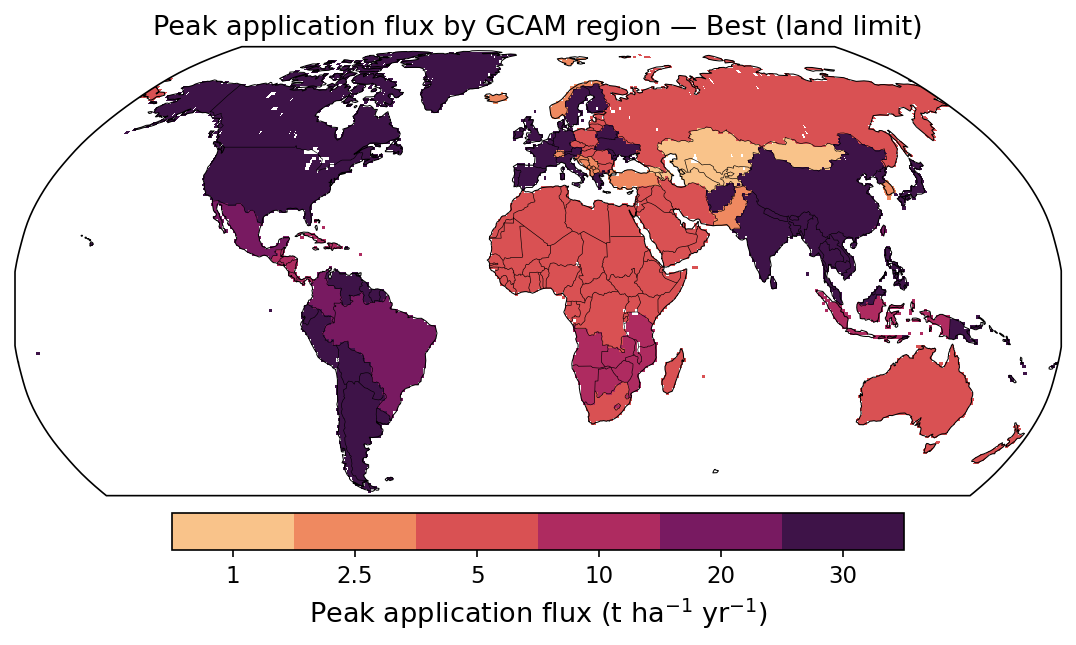

In [7]:
MAP_CASE = "best_lim"
MAP_CMAP = cmocean.cm.matter
MAP_EXTENT = (-181, 181, -57, 86)

reg_id_lookup = (dfs[FIXED_RATES[0]][["reg_id", "region_nospaces"]].drop_duplicates()
                 .set_index("region_nospaces")["reg_id"].to_dict())
dsag = xr.open_zarr(os.path.join(S3_GCAM, f"{FIXED_RATES[0]}-tHaYr-appRate-FIXED",
                                 f"cropland+gcamRegions_time_{DEG_RES}deg.zarr"))
reg_id_da = dsag["reg_id"]

# the flux levels are a discrete, near-geometric set, so map each one to an evenly spaced color
map_flux   = best[MAP_CASE].apprate_base.values
map_levels = rate_levels[np.isin(rate_levels, map_flux)]
level_idx  = {r: i for i, r in enumerate(map_levels)}
cmap = mcolors.ListedColormap(MAP_CMAP(np.linspace(0.12, 0.95, len(map_levels))))

vals = dict(zip((reg_id_lookup[s] for s in best[MAP_CASE].site.values),
                (level_idx[r] for r in map_flux)))
painted = xr.DataArray(
    np.vectorize(lambda r: vals.get(int(r), np.nan))(reg_id_da.values),
    coords=reg_id_da.coords, dims=reg_id_da.dims,
).where(dsag["cropland_area_by_region"] != 0)

fig, ax = plt.subplots(figsize=(9, 5), dpi=150, subplot_kw={"projection": ccrs.Robinson()})
p = painted.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap,
                 vmin=-0.5, vmax=len(map_levels) - 0.5, add_colorbar=True,
                 cbar_kwargs={"orientation": "horizontal", "pad": 0.03, "shrink": 0.7,
                              "ticks": np.arange(len(map_levels))})
p.colorbar.ax.set_xticklabels([f"{r:g}" for r in map_levels], fontsize=FS_TICK)
p.colorbar.set_label(r"Peak application flux (t ha$^{-1}$ yr$^{-1}$)", fontsize=FS_LAB)

ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
ax.coastlines(linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.3)
ax.set_title(f"Peak application flux by GCAM region — {CASE_LABEL[MAP_CASE]}", fontsize=FS_TITLE)
plt.show()

if SAVE_ON:
    fig.savefig(os.path.join(savehere, "appflux-map-peak.png"), dpi=300, bbox_inches="tight")